DATASET LOADED SUCCESSFULLY
Total Messages: 5169

Category Distribution:
label
ham     4516
spam     653
Name: count, dtype: int64

FEATURE EXTRACTION COMPLETED
Training Features: (4135, 7329)
Testing Features: (1034, 7329)

MODEL TRAINING COMPLETED

MODEL EVALUATION
Accuracy: 96.62 %

CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Not Spam       0.96      1.00      0.98       903
        Spam       0.99      0.74      0.85       131

    accuracy                           0.97      1034
   macro avg       0.98      0.87      0.91      1034
weighted avg       0.97      0.97      0.96      1034



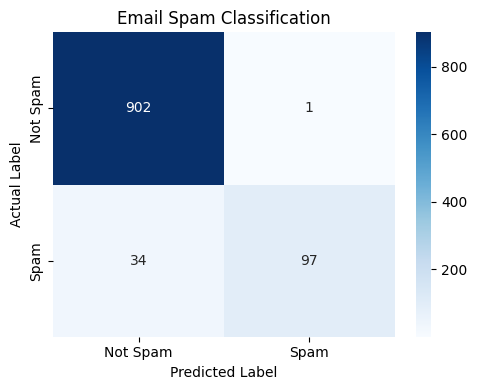


SAMPLE EMAIL PREDICTIONS
Congratulations! You won a free cash prize. Claim now! --> SPAM
Hello, please attend the meeting tomorrow at 10 AM. --> NOT SPAM
You have won a lottery. Click here to claim your reward. --> SPAM
Your assignment submission deadline is tomorrow. --> NOT SPAM

FINAL RESULT
Total Messages: 5169
Spam Messages: 653
Not Spam Messages: 4516
Model Accuracy: 96.62 %

PROJECT COMPLETED SUCCESSFULLY!


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# 1. Load Dataset
file_path = r"C:\Users\Hp\Downloads\spam.csv"

df = pd.read_csv(file_path, encoding="latin-1")

# Select required columns from SMS Spam Collection dataset
df = df[["v1", "v2"]]
df.columns = ["label", "message"]

# Remove missing and duplicate records
df = df.dropna()
df = df.drop_duplicates()

print("DATASET LOADED SUCCESSFULLY")
print("Total Messages:", len(df))
print("\nCategory Distribution:")
print(df["label"].value_counts())


# 2. Convert Labels
# ham = 0 (Not Spam)
# spam = 1 (Spam)

df["label"] = df["label"].map({
    "ham": 0,
    "spam": 1
})

X = df["message"].astype(str)
y = df["label"]


# 3. Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)


# 4. TF-IDF Feature Extraction
vectorizer = TfidfVectorizer(
    stop_words="english",
    lowercase=True
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print("\nFEATURE EXTRACTION COMPLETED")
print("Training Features:", X_train_tfidf.shape)
print("Testing Features:", X_test_tfidf.shape)


# 5. Train Naive Bayes Model
model = MultinomialNB()
model.fit(X_train_tfidf, y_train)

print("\nMODEL TRAINING COMPLETED")


# 6. Model Evaluation
y_pred = model.predict(X_test_tfidf)

accuracy = accuracy_score(y_test, y_pred)

print("\nMODEL EVALUATION")
print("Accuracy:", round(accuracy * 100, 2), "%")

print("\nCLASSIFICATION REPORT")

print(classification_report(
    y_test,
    y_pred,
    target_names=["Not Spam", "Spam"],
    zero_division=0
))


# 7. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Spam", "Spam"],
    yticklabels=["Not Spam", "Spam"]
)

plt.title("Email Spam Classification")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()


# 8. Sample Email Predictions
sample_emails = [
    "Congratulations! You won a free cash prize. Claim now!",
    "Hello, please attend the meeting tomorrow at 10 AM.",
    "You have won a lottery. Click here to claim your reward.",
    "Your assignment submission deadline is tomorrow."
]

sample_features = vectorizer.transform(sample_emails)
predictions = model.predict(sample_features)

print("\nSAMPLE EMAIL PREDICTIONS")

for email, prediction in zip(sample_emails, predictions):
    result = "SPAM" if prediction == 1 else "NOT SPAM"
    print(f"{email} --> {result}")


# 9. Final Output
print("\nFINAL RESULT")
print("Total Messages:", len(df))
print("Spam Messages:", (df["label"] == 1).sum())
print("Not Spam Messages:", (df["label"] == 0).sum())
print("Model Accuracy:", round(accuracy * 100, 2), "%")

print("\nPROJECT COMPLETED SUCCESSFULLY!")